In [1]:
## Imports
import torch
import torchvision ## Contains some utilities for working with the image data
from torchvision.datasets import MNIST
import matplotlib.pyplot as plt
#%matplotlib inline
import torchvision.transforms as transforms
from torch.utils.data import random_split
from torch.utils.data import DataLoader
import torch.nn.functional as F

# Loading the MNIST dataset

In [2]:
dataset = MNIST(root = 'data/', download = True)
print(len(dataset))

100%|██████████| 9.91M/9.91M [00:00<00:00, 49.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.68MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 14.9MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 14.3MB/s]

60000


Label: 3


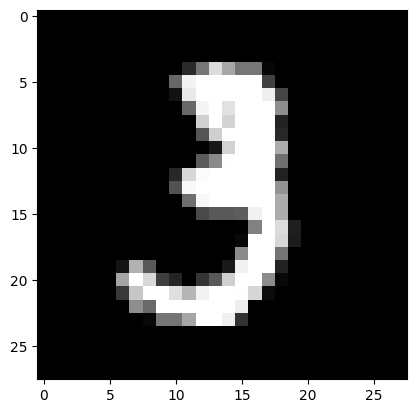

In [3]:
image, label = dataset[10]
plt.imshow(image, cmap = 'gray')
print('Label:', label)

# Loading the MNIST data with transformation applied while loading

In [4]:
## MNIST dataset(images and labels)
mnist_dataset = MNIST(root = 'data/', train = True, transform = transforms.ToTensor())
print(mnist_dataset)

Dataset MNIST
    Number of datapoints: 60000
    Root location: data/
    Split: Train
    StandardTransform
Transform: ToTensor()


In [5]:
image_tensor, label = mnist_dataset[0]
print(image_tensor.shape, label)

torch.Size([1, 28, 28]) 5


In [6]:
print(image_tensor[:,10:15,10:15])
print(torch.max(image_tensor), torch.min(image_tensor))

tensor([[[0.0039, 0.6039, 0.9922, 0.3529, 0.0000],
         [0.0000, 0.5451, 0.9922, 0.7451, 0.0078],
         [0.0000, 0.0431, 0.7451, 0.9922, 0.2745],
         [0.0000, 0.0000, 0.1373, 0.9451, 0.8824],
         [0.0000, 0.0000, 0.0000, 0.3176, 0.9412]]])
tensor(1.) tensor(0.)


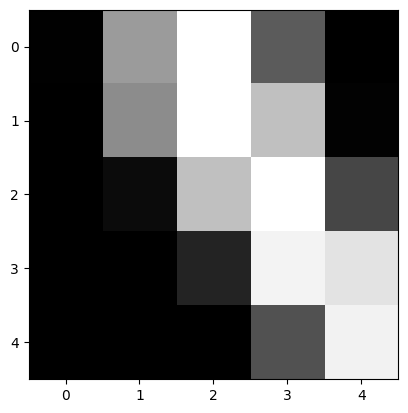

In [7]:
## Plot the image of the tensor
plt.imshow(image_tensor[0,10:15,10:15],cmap = 'gray')

**MNIST e transforms.ToTensor():** Carregam e convertem imagens em tensores numéricos que o modelo entende.

# Training and Validation Datasets

In [8]:
train_data, validation_data = random_split(mnist_dataset, [50000, 10000])
## Print the length of train and validation datasets
print("length of Train Datasets: ", len(train_data))
print("length of Validation Datasets: ", len(validation_data))

length of Train Datasets:  50000
length of Validation Datasets:  10000


**random_split:** Separa os dados em Treino (para o modelo aprender) e Validação (para testar se ele aprendeu corretamente e não apenas decorou).

In [9]:
batch_size = 128
train_loader = DataLoader(train_data, batch_size, shuffle = True)
val_loader = DataLoader(validation_data, batch_size, shuffle = False)

**DataLoader:** Organiza os dados em batches (lotes), permitindo que o computador processe pequenos pedaços por vez.

# Model

In [10]:
import torch.nn as nn

input_size = 28 * 28
num_classes = 10

## Logistic regression model
model = nn.Linear(input_size, num_classes)
print(model.weight.shape)
print(model.weight)
print(model.bias.shape)
print(model.bias)

torch.Size([10, 784])
Parameter containing:
tensor([[-0.0199, -0.0327, -0.0307,  ..., -0.0135,  0.0043,  0.0020],
        [-0.0031,  0.0166,  0.0016,  ...,  0.0058, -0.0112, -0.0145],
        [-0.0250, -0.0274, -0.0249,  ..., -0.0190, -0.0195, -0.0345],
        ...,
        [ 0.0153, -0.0113, -0.0249,  ..., -0.0142,  0.0203,  0.0090],
        [-0.0036, -0.0182,  0.0016,  ...,  0.0019, -0.0021,  0.0029],
        [ 0.0166, -0.0122,  0.0022,  ...,  0.0100,  0.0189,  0.0223]],
       requires_grad=True)
torch.Size([10])
Parameter containing:
tensor([ 0.0248, -0.0178, -0.0289, -0.0255, -0.0074,  0.0082,  0.0199,  0.0021,
         0.0072,  0.0039], requires_grad=True)


**nn.Linear(input_size, num_classes):** Define a estrutura. É uma Regressão Logística que tenta encontrar pesos (weights) que relacionam os 784 pixels da imagem às 10 classes possíveis (números de 0 a 9).

In [11]:
for images, labels in train_loader:
    print(labels)
    print(images.shape)
    # Flatten the images from (batch_size, 1, 28, 28) to (batch_size, 784)
    outputs = model(images.reshape(-1, 784))
    break

tensor([5, 4, 5, 0, 9, 1, 3, 4, 0, 7, 0, 5, 9, 8, 9, 7, 8, 7, 9, 7, 1, 0, 3, 0,
        8, 3, 9, 4, 4, 5, 6, 0, 2, 8, 0, 8, 1, 3, 5, 2, 3, 5, 2, 6, 6, 2, 6, 7,
        6, 1, 8, 4, 7, 3, 9, 9, 5, 3, 0, 2, 2, 0, 5, 4, 3, 5, 6, 9, 7, 1, 7, 0,
        1, 3, 5, 6, 8, 1, 9, 1, 9, 5, 6, 7, 4, 0, 4, 4, 7, 7, 0, 3, 1, 6, 9, 4,
        0, 7, 1, 8, 0, 9, 6, 6, 1, 6, 8, 4, 7, 6, 2, 7, 5, 6, 0, 7, 6, 2, 2, 8,
        2, 0, 0, 7, 4, 1, 7, 4])
torch.Size([128, 1, 28, 28])


# Defining the Logistic Model

In [12]:
class MnistModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(input_size, num_classes)

    def forward(self, xb):
        xb = xb.reshape(-1, 784)
        print(xb)
        out = self.linear(xb)
        print(out)
        return(out)

model = MnistModel()
print(model.linear.weight.shape, model.linear.bias.shape)
list(model.parameters())

torch.Size([10, 784]) torch.Size([10])


[Parameter containing:
 tensor([[-0.0058,  0.0083,  0.0062,  ...,  0.0216,  0.0035,  0.0231],
         [-0.0299, -0.0191,  0.0102,  ...,  0.0041, -0.0259, -0.0048],
         [-0.0011,  0.0227, -0.0290,  ...,  0.0161, -0.0206,  0.0278],
         ...,
         [ 0.0124, -0.0202, -0.0128,  ...,  0.0171,  0.0326, -0.0291],
         [ 0.0086, -0.0116,  0.0093,  ...,  0.0277,  0.0289,  0.0057],
         [-0.0046, -0.0308, -0.0351,  ..., -0.0037, -0.0230,  0.0148]],
        requires_grad=True),
 Parameter containing:
 tensor([-0.0235,  0.0020, -0.0077, -0.0343, -0.0134,  0.0184,  0.0098, -0.0309,
         -0.0212, -0.0141], requires_grad=True)]

**forward:** Define como o dado passa pelo modelo (neste caso, achatando a imagem de 2D para 1D).

In [13]:
for images, labels in train_loader:
    outputs = model(images)
    break

print('outputs shape: ', outputs.shape)
print('Sample outputs: \n', outputs[:2].data)

tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]])
tensor([[-0.2140, -0.0236,  0.0809,  ...,  0.2203,  0.4073,  0.5934],
        [-0.3406,  0.2885,  0.1473,  ...,  0.0968,  0.0999,  0.3277],
        [-0.3781, -0.2636, -0.0185,  ...,  0.0115, -0.0987,  0.4903],
        ...,
        [-0.0347,  0.1661, -0.2029,  ...,  0.0396,  0.6774,  0.4935],
        [-0.0892,  0.0068,  0.1474,  ...,  0.2837,  0.0527,  0.2603],
        [-0.4309, -0.0338,  0.0445,  ...,  0.3589, -0.0057,  0.2534]],
       grad_fn=<AddmmBackward0>)
outputs shape:  torch.Size([128, 10])
Sample outputs: 
 tensor([[-0.2140, -0.0236,  0.0809, -0.1212, -0.0445, -0.2872,  0.1455,  0.2203,
          0.4073,  0.5934],
        [-0.3406,  0.2885,  0.1473,  0.1807, -0.1584,  0.0022,  0.0493,  0.0968,
          0.0999,  0.3277]])


In [14]:
## Apply softmax for each output row
probs = F.softmax(outputs, dim = 1)

## chaecking at sample probabilities
print("Sample probabilities:\n", probs[:2].data)

print("\n")
## Add up the probabilities of an output row
print("Sum: ", torch.sum(probs[0]).item())
max_probs, preds = torch.max(probs, dim = 1)
print("\n")
print(preds)
print("\n")
print(max_probs)

Sample probabilities:
 tensor([[0.0722, 0.0874, 0.0970, 0.0793, 0.0856, 0.0671, 0.1035, 0.1115, 0.1345,
         0.1619],
        [0.0652, 0.1224, 0.1063, 0.1099, 0.0783, 0.0919, 0.0963, 0.1010, 0.1014,
         0.1273]])


Sum:  1.0


tensor([9, 9, 9, 8, 1, 7, 7, 8, 2, 7, 9, 9, 7, 7, 2, 9, 8, 7, 1, 7, 7, 7, 1, 8,
        3, 7, 7, 1, 9, 8, 7, 9, 7, 8, 7, 7, 9, 3, 1, 8, 9, 9, 3, 3, 3, 7, 7, 8,
        9, 7, 3, 3, 7, 3, 7, 6, 9, 3, 9, 7, 8, 8, 8, 3, 7, 7, 9, 3, 8, 1, 9, 6,
        7, 8, 2, 8, 7, 9, 7, 7, 9, 8, 8, 9, 3, 3, 9, 9, 5, 8, 9, 7, 1, 3, 8, 8,
        8, 9, 7, 9, 7, 9, 7, 7, 8, 3, 9, 1, 9, 3, 9, 9, 7, 9, 7, 6, 3, 7, 7, 7,
        9, 9, 3, 8, 9, 8, 7, 7])


tensor([0.1619, 0.1273, 0.1659, 0.1210, 0.1343, 0.1144, 0.1283, 0.1133, 0.1171,
        0.1218, 0.1402, 0.1385, 0.1482, 0.1577, 0.1280, 0.1184, 0.1330, 0.1270,
        0.1381, 0.1418, 0.1306, 0.1345, 0.1157, 0.1697, 0.1095, 0.1304, 0.1329,
        0.1289, 0.1365, 0.1199, 0.1551, 0.1480, 0.1311, 0.1491, 0.1309, 0.1309,
        0

In [15]:
labels

tensor([6, 6, 7, 6, 6, 3, 6, 9, 5, 1, 0, 5, 7, 7, 9, 9, 4, 8, 3, 4, 6, 3, 6, 0,
        7, 7, 1, 3, 0, 6, 8, 4, 7, 2, 8, 7, 2, 6, 3, 0, 9, 2, 4, 9, 5, 6, 8, 3,
        2, 8, 0, 0, 2, 7, 7, 5, 5, 5, 4, 3, 3, 5, 3, 5, 7, 2, 0, 5, 0, 6, 6, 2,
        7, 3, 7, 6, 6, 0, 2, 2, 6, 6, 8, 0, 7, 8, 4, 6, 7, 0, 5, 1, 6, 2, 9, 4,
        3, 7, 1, 7, 9, 9, 1, 3, 0, 5, 5, 8, 5, 2, 2, 0, 4, 3, 8, 1, 1, 1, 1, 1,
        0, 8, 0, 4, 4, 0, 1, 7])

# Evaluation Metric and Loss Function

In [16]:
def accuracy(outputs, labels):
    _, preds = torch.max(outputs, dim = 1)
    return(torch.tensor(torch.sum(preds == labels).item()/ len(preds)))

print("Accuracy: ",accuracy(outputs, labels))
print("\n")
loss_fn = F.cross_entropy
print("Loss Function: ",loss_fn)
print("\n")
## Loss for the current batch
loss = loss_fn(outputs, labels)
print(loss)


Accuracy:  tensor(0.1016)


Loss Function:  <function cross_entropy at 0x7e16c9981440>


tensor(2.3290, grad_fn=<NllLossBackward0>)


**cross_entropy:** A métrica de erro. Ela diz ao modelo o quão longe a previsão está da realidade.

Diferente da perda, a acurácia é uma medida humana: qual a porcentagem de imagens que o modelo acertou? É o que usamos para decidir se o modelo está bom o suficiente para ser usado.

In [17]:
for images, labels in train_loader:
    outputs = model(images)
    break

print('outputs shape: ', outputs.shape)
print('Sample outputs: \n', outputs[:2].data)

tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]])
tensor([[-0.1275,  0.0808, -0.0567,  ...,  0.0361, -0.1209, -0.0588],
        [-0.2315,  0.0555,  0.0068,  ...,  0.3911,  0.1151,  0.1916],
        [-0.2650, -0.1227,  0.1434,  ...,  0.4362,  0.4180,  0.2160],
        ...,
        [-0.5476, -0.0910,  0.0867,  ...,  0.0032,  0.2667,  0.3277],
        [-0.3158,  0.4073, -0.0923,  ...,  0.0635,  0.3126,  0.3625],
        [-0.4091, -0.2194,  0.0793,  ...,  0.1612,  0.4742,  0.5656]],
       grad_fn=<AddmmBackward0>)
outputs shape:  torch.Size([128, 10])
Sample outputs: 
 tensor([[-0.1275,  0.0808, -0.0567,  0.1279, -0.1046, -0.0193, -0.0962,  0.0361,
         -0.1209, -0.0588],
        [-0.2315,  0.0555,  0.0068,  0.2407, -0.1845, -0.1700, -0.1640,  0.3911,
          0.1151,  0.1916]])


# Training the Model

In [18]:
class MnistModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(input_size, num_classes)

    def forward(self, xb):
        xb = xb.reshape(-1, 784)
        out = self.linear(xb)
        return(out)

    def training_step(self, batch):
        images, labels = batch
        out = self(images) ## Generate predictions
        loss = F.cross_entropy(out, labels) ## Calculate the loss
        return(loss)

    def validation_step(self, batch):
        images, labels = batch
        out = self(images)
        loss = F.cross_entropy(out, labels)
        acc = accuracy(out, labels)
        return({'val_loss':loss, 'val_acc': acc})

    def validation_epoch_end(self, outputs):
        batch_losses = [x['val_loss'] for x in outputs]
        epoch_loss = torch.stack(batch_losses).mean()
        batch_accs = [x['val_acc'] for x in outputs]
        epoch_acc = torch.stack(batch_accs).mean()
        return({'val_loss': epoch_loss.item(), 'val_acc' : epoch_acc.item()})
    def epoch_end(self, epoch,result):
        print("Epoch [{}], val_loss: {:.4f}, val_acc: {:.4f}".format(epoch, result['val_loss'], result['val_acc']))


model = MnistModel()

In [19]:
def evaluate(model, val_loader):
    outputs = [model.validation_step(batch) for batch in val_loader]
    return(model.validation_epoch_end(outputs))

def fit(epochs, lr, model, train_loader, val_loader, opt_func = torch.optim.SGD):
    history = []
    optimizer = opt_func(model.parameters(), lr)
    for epoch in range(epochs):

        ## Training Phas
        for batch in train_loader:
            loss = model.training_step(batch)
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

        ## Validation phase
        result = evaluate(model, val_loader)
        model.epoch_end(epoch, result)
        history.append(result)
    return(history)

**optimizer.step() e loss.backward():** O algoritmo calcula o erro e ajusta os pesos do modelo para diminuir esse erro no futuro.

In [20]:
result0 = evaluate(model, val_loader)
result0

{'val_loss': 2.3040974140167236, 'val_acc': 0.10917721688747406}

In [21]:
history1 = fit(5, 0.001, model, train_loader, val_loader)

Epoch [0], val_loss: 1.9423, val_acc: 0.5988
Epoch [1], val_loss: 1.6756, val_acc: 0.7184
Epoch [2], val_loss: 1.4758, val_acc: 0.7596
Epoch [3], val_loss: 1.3246, val_acc: 0.7822
Epoch [4], val_loss: 1.2082, val_acc: 0.7994


In [22]:
history2 = fit(5, 0.001, model, train_loader, val_loader)

Epoch [0], val_loss: 1.1168, val_acc: 0.8081
Epoch [1], val_loss: 1.0434, val_acc: 0.8163
Epoch [2], val_loss: 0.9834, val_acc: 0.8218
Epoch [3], val_loss: 0.9334, val_acc: 0.8262
Epoch [4], val_loss: 0.8911, val_acc: 0.8307


In [23]:
history3 = fit(5, 0.001, model, train_loader, val_loader)

Epoch [0], val_loss: 0.8548, val_acc: 0.8355
Epoch [1], val_loss: 0.8234, val_acc: 0.8386
Epoch [2], val_loss: 0.7959, val_acc: 0.8408
Epoch [3], val_loss: 0.7716, val_acc: 0.8429
Epoch [4], val_loss: 0.7500, val_acc: 0.8455


In [24]:
history4 = fit(5, 0.001, model, train_loader, val_loader)

Epoch [0], val_loss: 0.7305, val_acc: 0.8478
Epoch [1], val_loss: 0.7130, val_acc: 0.8503
Epoch [2], val_loss: 0.6970, val_acc: 0.8523
Epoch [3], val_loss: 0.6825, val_acc: 0.8545
Epoch [4], val_loss: 0.6692, val_acc: 0.8559


Text(0.5, 1.0, 'Accuracy Vs. No. of epochs')

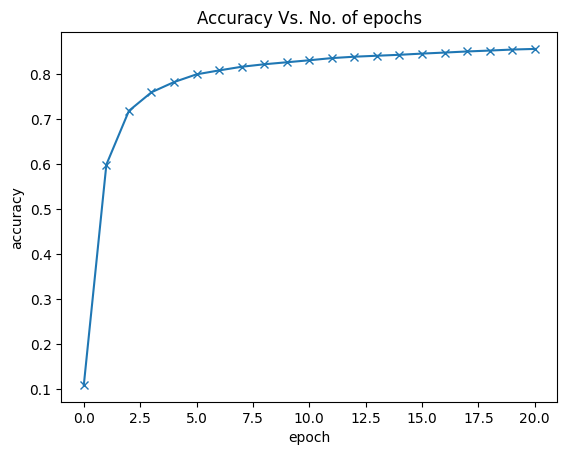

In [25]:
## Replace these values with your result
history = [result0] + history1 + history2 + history3 + history4
accuracies = [result['val_acc'] for result in history]
plt.plot(accuracies, '-x')
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.title('Accuracy Vs. No. of epochs')

# Testing with individual images

In [26]:
## Define the test dataset
test_dataset = MNIST(root = 'data/', train = False, transform = transforms.ToTensor())

shape:  torch.Size([1, 28, 28])
Label:  7


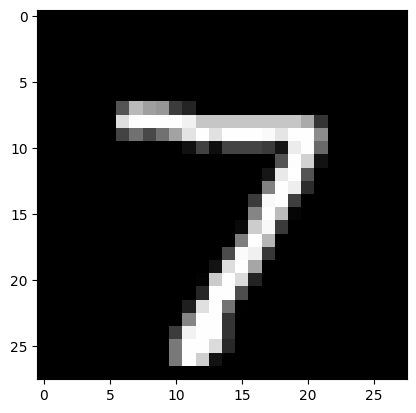

In [27]:
img, label = test_dataset[0]
plt.imshow(img[0], cmap = 'gray')
print("shape: ", img.shape)
print('Label: ', label)

In [28]:
print(img.unsqueeze(0).shape)
print(img.shape)

torch.Size([1, 1, 28, 28])
torch.Size([1, 28, 28])


In [29]:
def predict_image(img, model):
    xb = img.unsqueeze(0)
    yb = model(xb)
    _, preds = torch.max(yb, dim = 1)
    return(preds[0].item())

Label: 7 , Predicted : 7


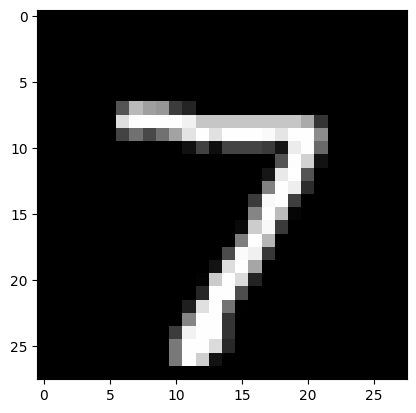

In [30]:
img, label = test_dataset[0]
plt.imshow(img[0], cmap = 'gray')
print('Label:', label, ', Predicted :', predict_image(img, model))

Label: 9 ,Predicted: 9


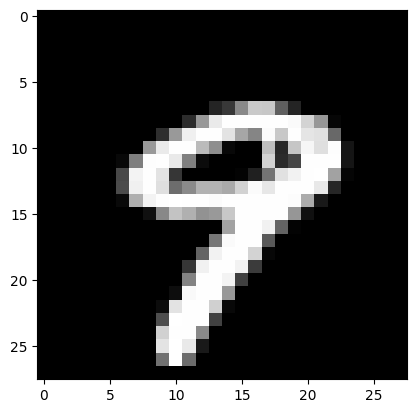

In [31]:
img, label = test_dataset[9]
plt.imshow(img[0], cmap = 'gray')
print("Label:", label, ',Predicted:', predict_image(img, model))

Label: 0 ,Predicted: 0


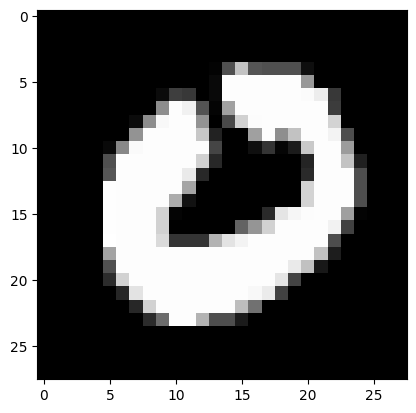

In [32]:
img, label = test_dataset[25]
plt.imshow(img[0], cmap = 'gray')
print("Label:", label, ',Predicted:', predict_image(img, model))

Label: 3 ,Predicted: 3


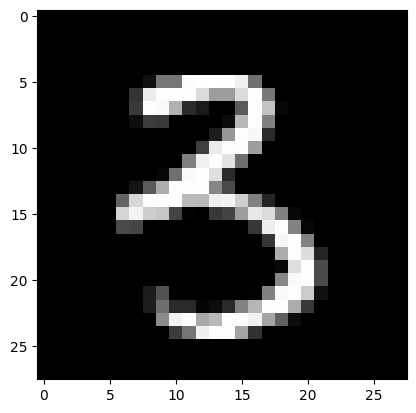

In [33]:
img, label = test_dataset[5000]
plt.imshow(img[0], cmap = 'gray')
print("Label:", label, ',Predicted:', predict_image(img, model))

In [34]:
test_loader = DataLoader(test_dataset, batch_size = 256)
result = evaluate(model, test_loader)
result

{'val_loss': 0.640388011932373, 'val_acc': 0.86279296875}